# Hybrid CNN-LSTM

Builds a TimeDistributed Conv1D over per-timestep features followed by LSTM for temporal modeling, trains/evaluates, compares against pure CNN and pure LSTM baselines, and saves the best model.

In [1]:

import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder

try:
    import tensorflow as tf
except ImportError:
    raise ImportError("TensorFlow not installed. Please: pip install tensorflow")
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
np.random.seed(42)
try:
    tf.random.set_seed(42)
except Exception:
    pass

from schema_utils import detect_feature_columns, infer_session_sort_columns, create_sequences

2025-10-26 22:20:15.896836: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/Users/lap/Documents/Arduino/lampochka/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:

# Load dataset (zone-only features for sequences)
DATA_DIR = os.path.join('..','datasets')
TRAIN_PATH = os.path.join(DATA_DIR, 'training_data_train.csv')
TEST_PATH = os.path.join(DATA_DIR, 'training_data_test.csv')
if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
    raise FileNotFoundError("Missing train/test CSVs in ../datasets: training_data_train.csv and training_data_test.csv")


df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)
from schema_utils import detect_feature_columns, infer_session_sort_columns, create_sequences
schema = detect_feature_columns(df_train)
if not schema['label_col']:
    raise ValueError('No label column detected. Expected one of: label/class/target')
feature_cols = schema['zone_cols']
label_col = schema['label_col']
session_col_train, sort_col_train = infer_session_sort_columns(df_train)
session_col_test, sort_col_test = infer_session_sort_columns(df_test)
SEQ_LEN = 10
X_train_sequences, y_str_train = create_sequences(df_train, SEQ_LEN, feature_cols, label_col, session_col_train, sort_col_train)
X_test_sequences, y_str_test = create_sequences(df_test, SEQ_LEN, feature_cols, label_col, session_col_test, sort_col_test)
le = LabelEncoder()
y_train = le.fit_transform(y_str_train)
y_test = le.transform(y_str_test)

print('Train sequences:', X_train_sequences.shape, 'Test sequences:', X_test_sequences.shape)
print('Classes:', list(le.classes_))
print('Zone source:', schema['zone_source'], 'Zone count:', len(feature_cols))


Train sequences: (1412, 10, 46) Test sequences: (424, 10, 46)
Classes: ['human', 'nothing']
Zone source: fallback_numeric Zone count: 46


In [3]:

# Prepare sequence data for CNN-LSTM
session_candidates = ['session_id','session','recording_id','recording','seq_id']
sort_candidates = ['timestep','timestamp','frame','time']
session_col = next((c for c in session_candidates if c in df_train.columns), None)
sort_col = next((c for c in sort_candidates if c in df_train.columns), None)
if session_col is None:
    session_col = '__synthetic_session__'
    df_train[session_col] = 0
    df_test[session_col] = 0
    print('Warning: No session column found; using single synthetic session.')
else:
    print('Using session column:', session_col)
if sort_col is None:
    df_train['__row_index__'] = np.arange(len(df_train))
    df_test['__row_index__'] = np.arange(len(df_test))
    sort_col = '__row_index__'
    print('Warning: No timestamp/timestep column found; using row order.')
else:
    print('Using sort column:', sort_col)

SEQ_LEN = 10  # per spec

# Create sliding windows per session

# Using schema_utils.create_sequences

print('Train sequences:', X_train_sequences.shape, 'Test sequences:', X_test_sequences.shape)


# Shapes for models
X_train_lstm = X_train_sequences
X_test_lstm = X_test_sequences
X_train_cnnlstm = X_train_sequences.reshape(-1, SEQ_LEN, len(feature_cols), 1)
X_test_cnnlstm = X_test_sequences.reshape(-1, SEQ_LEN, len(feature_cols), 1)
X_train_cnn = X_train_sequences[:, -1, :].reshape(-1, len(feature_cols), 1)
X_test_cnn = X_test_sequences[:, -1, :].reshape(-1, len(feature_cols), 1)


print('Train shapes:', X_train_lstm.shape, X_train_cnnlstm.shape, X_train_cnn.shape)
print('Test shapes:', X_test_lstm.shape, X_test_cnnlstm.shape, X_test_cnn.shape)


Train sequences: (1412, 10, 46) Test sequences: (424, 10, 46)
Train shapes: (1412, 10, 46) (1412, 10, 46, 1) (1412, 46, 1)
Test shapes: (424, 10, 46) (424, 10, 46, 1) (424, 46, 1)


In [4]:

# Hybrid CNN-LSTM per spec

def build_cnn_lstm():
    model = keras.Sequential([
        layers.Input(shape=(SEQ_LEN, len(feature_cols), 1)),
        layers.TimeDistributed(layers.Conv1D(16, 3, activation='relu', padding='same')),
        layers.TimeDistributed(layers.MaxPooling1D(pool_size=2)),
        layers.TimeDistributed(layers.Flatten()),
        layers.LSTM(32, dropout=0.2),
        layers.Dense(16, activation='relu'),
        layers.Dense(3, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Pure LSTM baseline

def build_lstm():
    model = keras.Sequential([
        layers.Input(shape=(SEQ_LEN, len(feature_cols))),
        layers.LSTM(32, return_sequences=True, dropout=0.2, recurrent_dropout=0.2),
        layers.LSTM(16, return_sequences=False, dropout=0.2),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(3, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Pure CNN baseline (last frame only)

def build_cnn():
    model = keras.Sequential([
        layers.Input(shape=(len(feature_cols), 1)),
        layers.Conv1D(16, 3, activation='relu', padding='same'),
        layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(32, 3, activation='relu', padding='same'),
        layers.Flatten(),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(3, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model


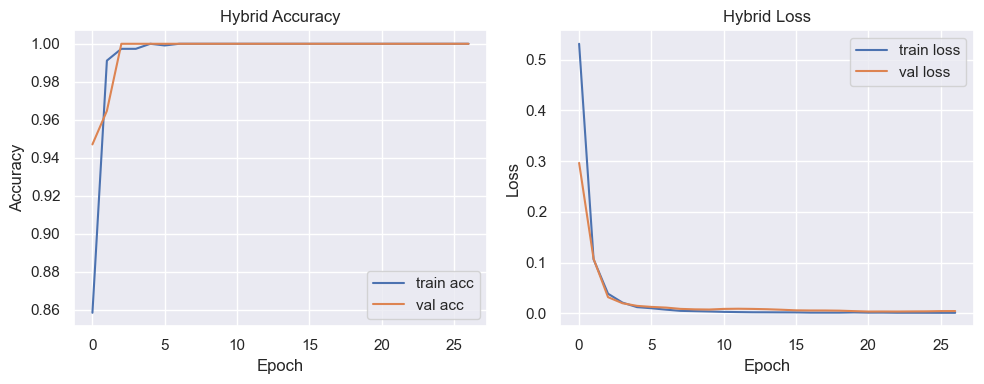

Hybrid accuracy (thresholded 0.7): 0.9127358490566038
              precision    recall  f1-score   support

       human       0.85      1.00      0.92       210
     nothing       1.00      0.83      0.91       214

    accuracy                           0.91       424
   macro avg       0.93      0.91      0.91       424
weighted avg       0.93      0.91      0.91       424



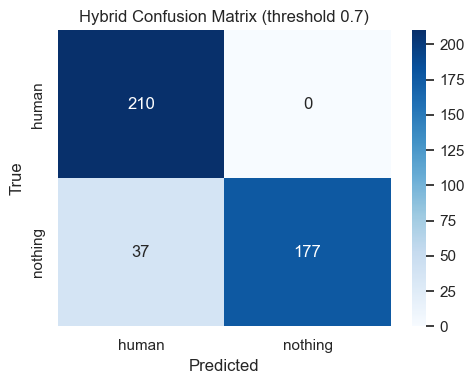

,model,test_accuracy,training_time_s,params
0,CNN-LSTM,0.912736,31.385457,51971
1,LSTM,0.910377,20.285478,13571
2,CNN,0.898585,9.162609,13475


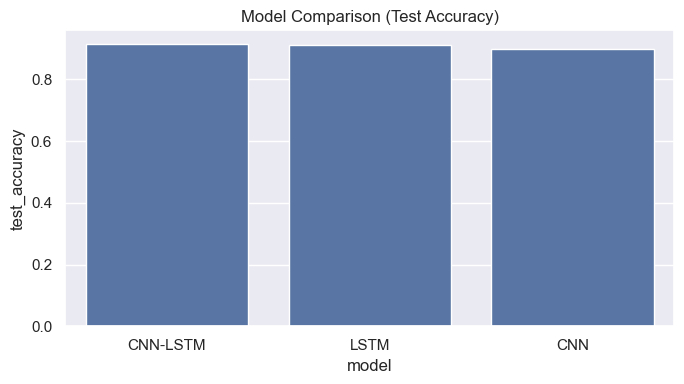

Best model: CNN-LSTM Accuracy: 0.9127358490566038
Saved hybrid model to ../models/cnn_lstm_model.h5
Saved best model to ../models/cnn_lstm_best.h5
Saved metadata to cnn_lstm_meta.json


In [10]:

# Callbacks
es = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
rlr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5)

# Train hybrid
hybrid = build_cnn_lstm()
start = time.time()
hist_h = hybrid.fit(X_train_cnnlstm, y_train, epochs=50, batch_size=64, validation_split=0.2,
                    callbacks=[es, rlr], verbose=0)
train_time_h = time.time() - start
acc_h = hybrid.evaluate(X_test_cnnlstm, y_test, verbose=0)[1]
params_h = hybrid.count_params()

# Plot hybrid training history
hist_df_h = pd.DataFrame(hist_h.history)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(hist_df_h['accuracy'], label='train acc')
plt.plot(hist_df_h['val_accuracy'], label='val acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Hybrid Accuracy'); plt.legend()
plt.subplot(1,2,2)
plt.plot(hist_df_h['loss'], label='train loss')
plt.plot(hist_df_h['val_loss'], label='val loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Hybrid Loss'); plt.legend()
plt.tight_layout(); plt.show()

# Evaluate hybrid with probability threshold 0.7
probs_h = hybrid.predict(X_test_cnnlstm, verbose=0)
preds_h_raw = np.argmax(probs_h, axis=1)
max_probs_h = np.max(probs_h, axis=1)
nothing_int = le.transform(['nothing'])[0]
preds_h_thresh = np.where(max_probs_h >= 0.95, preds_h_raw, nothing_int)
acc_h_thresh = np.mean(preds_h_thresh == y_test)
cm_h = confusion_matrix(y_test, preds_h_thresh)
print('Hybrid accuracy (thresholded 0.7):', acc_h_thresh)
print(classification_report(y_test, preds_h_thresh, target_names=list(le.classes_)))
plt.figure(figsize=(5,4))
sns.heatmap(cm_h, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Hybrid Confusion Matrix (threshold 0.7)'); plt.xlabel('Predicted'); plt.ylabel('True'); plt.tight_layout(); plt.show()

# Train LSTM baseline
lstm = build_lstm()
start = time.time()
hist_l = lstm.fit(X_train_lstm, y_train, epochs=50, batch_size=64, validation_split=0.2,
                  callbacks=[es, rlr], verbose=0)
train_time_l = time.time() - start
acc_l = lstm.evaluate(X_test_lstm, y_test, verbose=0)[1]
params_l = lstm.count_params()

# Train CNN baseline
cnn = build_cnn()
start = time.time()
hist_c = cnn.fit(X_train_cnn, y_train, epochs=50, batch_size=64, validation_split=0.2,
                 callbacks=[es, rlr], verbose=0)
train_time_c = time.time() - start
acc_c = cnn.evaluate(X_test_cnn, y_test, verbose=0)[1]
params_c = cnn.count_params()

# Comparison table
comp = pd.DataFrame([
    {'model':'CNN-LSTM', 'test_accuracy': acc_h_thresh, 'training_time_s': train_time_h, 'params': params_h},
    {'model':'LSTM',     'test_accuracy': acc_l, 'training_time_s': train_time_l, 'params': params_l},
    {'model':'CNN',      'test_accuracy': acc_c, 'training_time_s': train_time_c, 'params': params_c},
]).sort_values('test_accuracy', ascending=False)
display(comp)
plt.figure(figsize=(7,4))
sns.barplot(x='model', y='test_accuracy', data=comp)
plt.title('Model Comparison (Test Accuracy)'); plt.tight_layout(); plt.show()

best_row = comp.iloc[0]
print('Best model:', best_row['model'], 'Accuracy:', best_row['test_accuracy'])

# Save best and hybrid
hybrid_path = os.path.join('..','models','cnn_lstm_model.h5')
hybrid.save(hybrid_path)
print('Saved hybrid model to', hybrid_path)

best_path = os.path.join('..','models','cnn_lstm_best.h5')
if best_row['model'] == 'CNN-LSTM':
    hybrid.save(best_path)
elif best_row['model'] == 'LSTM':
    lstm.save(best_path)
else:
    cnn.save(best_path)
print('Saved best model to', best_path)

# Metadata
meta = {
    'sequence_length': SEQ_LEN,
    'feature_columns': feature_cols,
    'classes': list(le.classes_),
    'comparison': comp.to_dict(orient='records'),
}
with open(os.path.join('..','models','cnn_lstm_meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)
print('Saved metadata to cnn_lstm_meta.json')
